# Camino del terreno — Fase 1: cuencas candidatas

Objetivo: delimitar las cuencas de todas las quebradas que desembocan en el Rímac o en el Santa Eulalia dentro del recorte del FABDEM.

- **Cauce principal**: Rímac y Santa Eulalia.
- ***Pour point*** (punto de salida): la última celda de un cauce lateral antes de unirse al cauce principal.
- **Cuenca**: todas las celdas cuyo flujo D8 pasa por el *pour point* (`watershed` de Whitebox).

Todo es local; las salidas van a `terreno/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import rasterio
from rasterio import features
from rasterio.warp import transform as warp_transform
from scipy import ndimage as ndi
from scipy.signal import find_peaks
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import whitebox

# --- Parámetros ---
UMBRAL_CAUCE = 500         # celdas (0.45 km²). Elegido en la fase 3 (mayor F1 contra ANA Estudios); antes 1000.
CORTE_PRINCIPAL = 50_000   # celdas (45 km²). Corte de acumulación para el cauce principal (ver paso 3).
CELDA_M2 = 30 * 30

# --- Rutas (el notebook vive en terreno/) ---
TERRENO = Path.cwd().resolve()
RAIZ = TERRENO.parent
DEM = RAIZ / "fabdem_chosica_hydro.tif"
FDIR = RAIZ / "flow_direction_d8.tif"
FACC = RAIZ / "flow_accumulation_d8.tif"

wbt = whitebox.WhiteboxTools()
wbt.set_verbose_mode(False)
print("Carpeta de trabajo:", TERRENO)
print("WhiteboxTools", wbt.version().split()[1] if wbt.version() else "")

Carpeta de trabajo: C:\Users\Camil\Desktop\CV u otras vainas\Hackaton SAS\terreno
WhiteboxTools v2.4.0


## Paso 2 — Revisión de los rasters
Si CRS, tamaño, resolución y *transform* coinciden, la celda (fila, col) es el mismo lugar en los tres.

In [2]:
filas = []
for ruta in [DEM, FDIR, FACC]:
    with rasterio.open(ruta) as src:
        a = src.read(1)
        filas.append({
            "archivo": ruta.name, "crs": str(src.crs), "ancho": src.width, "alto": src.height,
            "res_m": src.res[0], "nodata": src.nodata, "dtype": src.dtypes[0],
            "celdas_nodata": int((a == src.nodata).sum()), "transform": tuple(round(v, 3) for v in src.transform[:6]),
        })
revision = pd.DataFrame(filas)
display(revision.drop(columns="transform"))
print("Mismo transform en los 3:", revision["transform"].nunique() == 1)
print("Misma máscara NoData:", revision["celdas_nodata"].nunique() == 1)

,archivo,crs,ancho,alto,res_m,nodata,dtype,celdas_nodata
0,fabdem_chosica_hydro.tif,EPSG:32718,1097,930,30.0,-9999.0,float64,13744
1,flow_direction_d8.tif,EPSG:32718,1097,930,30.0,-32768.0,int16,13744
2,flow_accumulation_d8.tif,EPSG:32718,1097,930,30.0,-32768.0,float32,13744


Mismo transform en los 3: True
Misma máscara NoData: True


In [3]:
with rasterio.open(DEM) as src:
    dem = src.read(1); perfil = src.profile; T = src.transform; CRS = src.crs
with rasterio.open(FDIR) as src:
    fdir = src.read(1)
with rasterio.open(FACC) as src:
    acc = src.read(1); nd_acc = src.nodata

valido = acc != nd_acc
R, C = acc.shape
# "Borde" = celda válida vecina de NoData o del límite del archivo (la NoData forma un marco por la reproyección).
borde = valido & ~ndi.binary_erosion(valido, structure=np.ones((3, 3)), border_value=0)

# D8 de Whitebox: 1=NE, 2=E, 4=SE, 8=S, 16=SO, 32=O, 64=NO, 128=N
D8 = {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0), 16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}
idx = np.arange(R * C).reshape(R, C)
abajo = np.full(R * C, -1)                     # índice de la celda aguas abajo (-1 = sale del raster)
for d, (dr, dc) in D8.items():
    rr, cc = np.where((fdir == d) & valido)
    r2, c2 = rr + dr, cc + dc
    ok = (r2 >= 0) & (r2 < R) & (c2 >= 0) & (c2 < C)
    ok[ok] &= valido[r2[ok], c2[ok]]
    abajo[idx[rr[ok], cc[ok]]] = idx[r2[ok], c2[ok]]

# Salida final de cada celda (por "saltos de puntero")
salida_final = np.where(abajo < 0, np.arange(R * C), abajo)
for _ in range(30):
    salida_final = salida_final[salida_final]
salida_final = salida_final.reshape(R, C)

def trazar(r, c):
    # Camino D8 aguas abajo desde (r, c) hasta salir del área válida.
    camino = [(r, c)]
    while abajo[idx[r, c]] >= 0:
        r, c = divmod(int(abajo[idx[r, c]]), C)
        camino.append((r, c))
    return camino

# Hillshade (solo para las figuras)
def hillshade(z, az=315, alt=45):
    z = np.where(valido, z, np.nan)
    gy, gx = np.gradient(z, 30)
    pend = np.arctan(np.hypot(gx, gy)); asp = np.arctan2(-gx, gy)
    az, alt = np.radians(360 - az + 90), np.radians(alt)
    hs = np.sin(alt) * np.cos(pend) + np.cos(alt) * np.sin(pend) * np.cos(az - asp)
    return np.ma.masked_invalid(hs)
hs = hillshade(dem)
print("Celdas válidas:", int(valido.sum()), "| celdas de borde:", int(borde.sum()))

Celdas válidas: 1006466 | celdas de borde: 4048


## Paso 3 — Cauces principales (Rímac y Santa Eulalia)

Problemas de un corte de acumulación simple:
- El Rímac y el Santa Eulalia **entran** al recorte con acumulación casi 0 (su cuenca alta queda fuera), así que el corte no llega al borde por donde entran.
- Hay otros cauces grandes que **no** desembocan en el Rímac dentro del recorte: Huaycoloro (sale por el borde oeste) y un cauce de la vertiente del Lurín (sale por el sur).

Por eso primero ubico dónde entran y salen los ríos: son los mínimos de valle con mayor prominencia en cada borde.

In [4]:
def perfil_borde(lado):
    # Primera celda válida desde cada lado del raster.
    pts = []
    if lado in ("derecho", "izquierdo"):
        for r in range(R):
            cs = np.flatnonzero(valido[r])
            if len(cs): pts.append((r, cs.max() if lado == "derecho" else cs.min()))
    else:
        for c in range(C):
            rs = np.flatnonzero(valido[:, c])
            if len(rs): pts.append((rs.min() if lado == "superior" else rs.max(), c))
    return np.array(pts)

def valle_principal(lado):
    pts = perfil_borde(lado); z = dem[pts[:, 0], pts[:, 1]]
    pk, pr = find_peaks(-z, prominence=150)
    k = pk[np.argmax(pr["prominences"])]
    return tuple(int(v) for v in pts[k]), float(pr["prominences"].max())

entrada_rimac, prom_r = valle_principal("derecho")
entrada_se, prom_s = valle_principal("superior")
salida_rimac = np.unravel_index(np.argmax(np.where(borde, acc, 0)), acc.shape)   # borde con acumulación máxima

traza_rimac = trazar(*entrada_rimac)
traza_se = trazar(*entrada_se)
set_rimac = set(traza_rimac)
confluencia = next(p for p in traza_se if p in set_rimac)
traza_se = traza_se[:traza_se.index(confluencia)]       # Santa Eulalia hasta antes de unirse al Rímac

print(f"Entrada Rímac (borde derecho): {entrada_rimac}, z={dem[entrada_rimac]:.0f} m, prominencia {prom_r:.0f} m")
print(f"Entrada Santa Eulalia (borde superior): {entrada_se}, z={dem[entrada_se]:.0f} m, prominencia {prom_s:.0f} m")
print(f"Salida Rímac: {tuple(int(v) for v in salida_rimac)}, acumulación {acc[salida_rimac]:.0f} celdas")
print(f"Trazo Rímac termina en la salida: {traza_rimac[-1] == tuple(salida_rimac)} ({len(traza_rimac)*30/1000:.1f} km de celdas)")
print(f"Confluencia Santa Eulalia–Rímac: {confluencia}")

# Otras salidas grandes por el borde (no son el Rímac)
id_rimac = salida_final[salida_rimac]
otras = {}
for nombre, lado in [("oeste", "izquierdo"), ("sur", "inferior")]:
    pts = perfil_borde(lado); a = acc[pts[:, 0], pts[:, 1]]
    a = np.where(salida_final[pts[:, 0], pts[:, 1]] == id_rimac, 0, a)
    k = np.argmax(a); otras[nombre] = (tuple(int(v) for v in pts[k]), int(a[k]))
print("Mayores salidas que NO son el Rímac:", otras, "← oeste ≈ Huaycoloro; sur ≈ vertiente del Lurín")

Entrada Rímac (borde derecho): (420, 1092), z=1353 m, prominencia 1402 m
Entrada Santa Eulalia (borde superior): (2, 820), z=1625 m, prominencia 1825 m
Salida Rímac: (764, 5), acumulación 485791 celdas
Trazo Rímac termina en la salida: True (34.1 km de celdas)
Confluencia Santa Eulalia–Rímac: (456, 667)
Mayores salidas que NO son el Rímac: {'oeste': ((503, 3), 178364), 'sur': ((926, 423), 198234)} ← oeste ≈ Huaycoloro; sur ≈ vertiente del Lurín


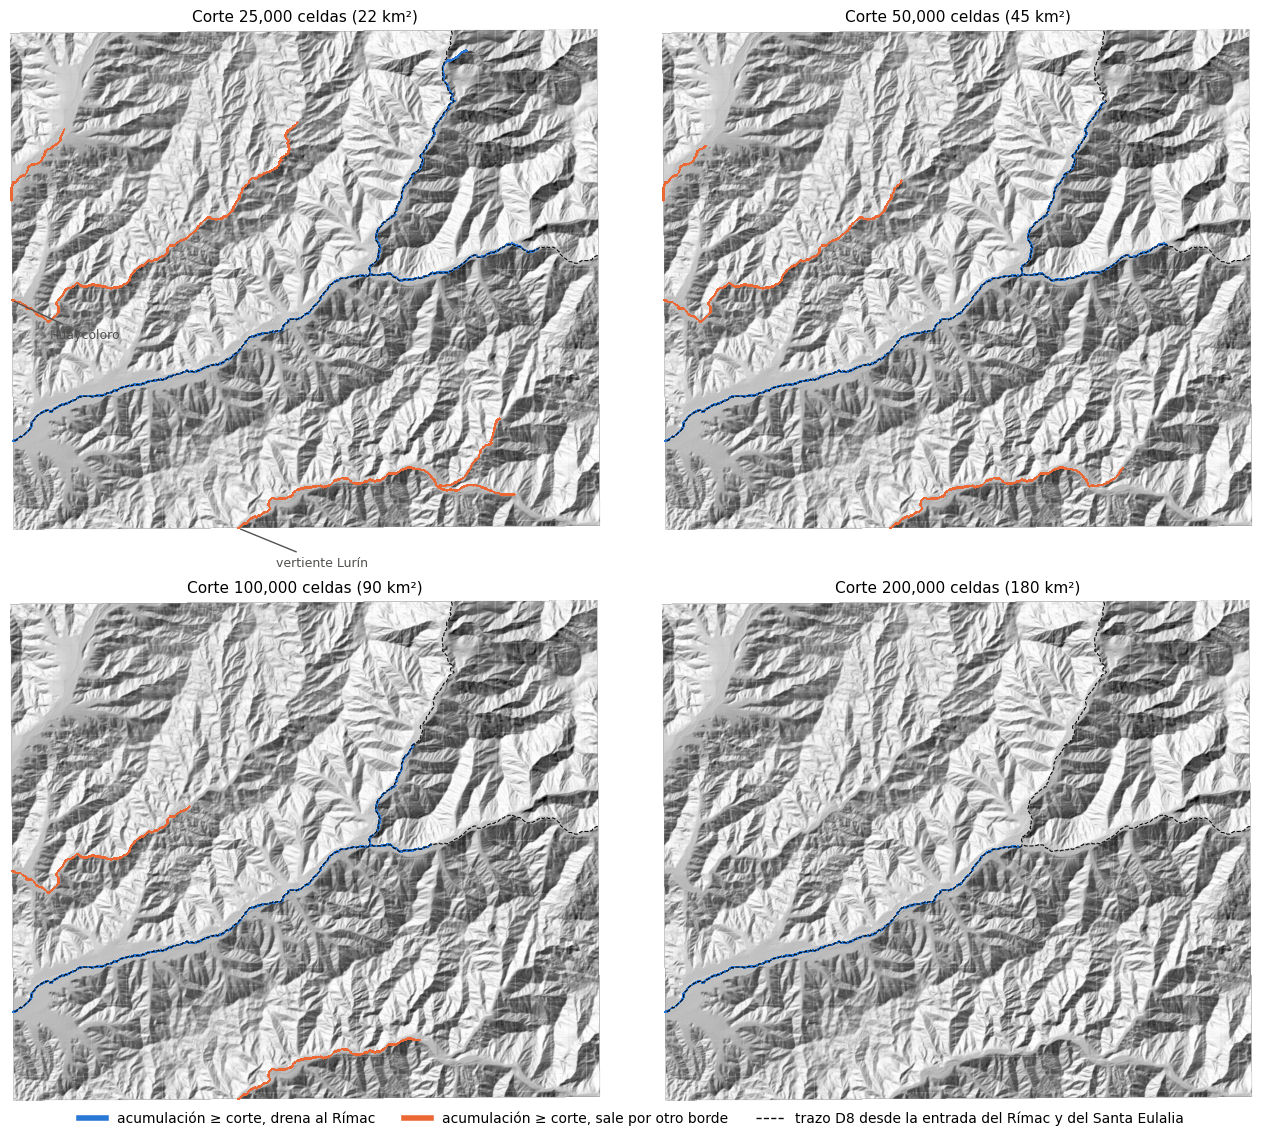

,corte_celdas,corte_km2,ramas_laterales_confundidas,celdas_a_otras_salidas,rimac_cubierto_pct,se_cubierto_pct,rimac_falta_desde_entrada_km
0,25000,22.5,1,1573,90,87,3.5
1,50000,45.0,0,1140,86,71,4.8
2,100000,90.0,0,752,72,42,9.5
3,200000,180.0,0,0,62,0,12.9


In [5]:
cortes = [25_000, 50_000, 100_000, 200_000]
traza_main = np.zeros((R, C), bool)
for p in traza_rimac + traza_se:
    traza_main[p] = True
drena_rimac = salida_final == id_rimac

filas = []
fig, axes = plt.subplots(2, 2, figsize=(13, 11), constrained_layout=True)
for ax, corte in zip(axes.flat, cortes):
    m = (acc >= corte) & valido
    al_rimac, a_otra = m & drena_rimac, m & ~drena_rimac
    ramas, n_ramas = ndi.label(al_rimac & ~traza_main, np.ones((3, 3)))
    cub_r = np.mean([acc[p] >= corte for p in traza_rimac])
    cub_s = np.mean([acc[p] >= corte for p in traza_se])
    i0 = next(i for i, p in enumerate(traza_rimac) if acc[p] >= corte)
    filas.append({"corte_celdas": corte, "corte_km2": corte * CELDA_M2 / 1e6,
                  "ramas_laterales_confundidas": n_ramas, "celdas_a_otras_salidas": int(a_otra.sum()),
                  "rimac_cubierto_pct": round(100 * cub_r), "se_cubierto_pct": round(100 * cub_s),
                  "rimac_falta_desde_entrada_km": round(i0 * 0.03, 1)})
    ax.imshow(hs, cmap="gray", vmin=-0.2, vmax=1.0)
    rr, cc = zip(*traza_rimac); ax.plot(cc, rr, color="#0b0b0b", lw=0.8, ls="--")
    rr, cc = zip(*traza_se); ax.plot(cc, rr, color="#0b0b0b", lw=0.8, ls="--")
    for capa, color in [(al_rimac, "#2a78d6"), (a_otra, "#eb6834")]:
        ax.imshow(np.ma.masked_where(~ndi.binary_dilation(capa, iterations=2), capa), cmap=ListedColormap([color]), interpolation="nearest")
    ax.set_title(f"Corte {corte:,} celdas ({corte*CELDA_M2/1e6:.0f} km²)", fontsize=11)
    ax.set_axis_off()
for (r, c), txt in [(otras["oeste"][0], "Huaycoloro"), (otras["sur"][0], "vertiente Lurín")]:
    axes.flat[0].annotate(txt, (c, r), xytext=(c + 70, r + 70), fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color="#52514e"))
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([], [], color="#2a78d6", lw=4, label="acumulación ≥ corte, drena al Rímac"),
                    Line2D([], [], color="#eb6834", lw=4, label="acumulación ≥ corte, sale por otro borde"),
                    Line2D([], [], color="#0b0b0b", lw=1, ls="--", label="trazo D8 desde la entrada del Rímac y del Santa Eulalia")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.03), frameon=False)
plt.show()
tabla_cortes = pd.DataFrame(filas)
display(tabla_cortes)

**Elección.** Ningún corte por sí solo da un cauce continuo que cruce el recorte. Elijo **50 000 celdas (45 km²)** porque:
- es el corte más bajo que no confunde ninguna quebrada lateral con un río: el tributario más grande tiene unos 26 000 celdas (23 km²);
- de los cortes que no confunden quebradas, es el que más cubre del Rímac y el Santa Eulalia;
- Huaycoloro y la vertiente del Lurín los quito con un filtro de conectividad: solo cuentan las celdas que **drenan a la salida del Rímac**;
- el tramo truncado aguas arriba lo completo con el trazo D8 desde los puntos de entrada.

In [6]:
principal = ((acc >= CORTE_PRINCIPAL) & drena_rimac) | traza_main
n_comp = ndi.label(principal, np.ones((3, 3)))[1]
print("Componentes conectados del cauce principal:", n_comp)
print("Toca el borde en la entrada del Rímac, la del Santa Eulalia y la salida:",
      all(principal[p] and borde[p] for p in [entrada_rimac, entrada_se, tuple(salida_rimac)]))
print("Celdas del principal que drenan a Huaycoloro o al Lurín:", int((principal & ~drena_rimac).sum()))
print("Celdas fuera del trazo D8 (debería ser 0):", int((principal & ~traza_main).sum()))

rio = np.zeros((R, C), np.uint8)              # 1 = Rímac, 2 = Santa Eulalia
for p in traza_rimac: rio[p] = 1
for p in traza_se: rio[p] = 2
perfil_u8 = perfil.copy(); perfil_u8.update(dtype="uint8", nodata=0, compress="lzw")
with rasterio.open(TERRENO / "cauce_principal.tif", "w", **perfil_u8) as dst:
    dst.write(rio, 1)

Componentes conectados del cauce principal: 1
Toca el borde en la entrada del Rímac, la del Santa Eulalia y la salida: True
Celdas del principal que drenan a Huaycoloro o al Lurín: 0
Celdas fuera del trazo D8 (debería ser 0): 0


## Paso 4 — Puntos de salida
- **Cauce lateral**: celda con acumulación ≥ `UMBRAL_CAUCE` que no es cauce principal.
- ***Pour point***: celda de cauce lateral cuya celda de aguas abajo ya es cauce principal.

Los `cuenca_id` se numeran desde la salida del Rímac hacia arriba y luego por el Santa Eulalia desde la confluencia hacia arriba.

In [7]:
lateral = (acc >= UMBRAL_CAUCE) & valido & ~principal
rr, cc = np.where(lateral)
ab = abajo[idx[rr, cc]]
es_pp = ab >= 0
es_pp[es_pp] &= principal.ravel()[ab[es_pp]]
pp_r, pp_c, pp_ab = rr[es_pp], cc[es_pp], ab[es_pp]

# Posición de la unión a lo largo del río (km desde la salida del Rímac, o desde la confluencia para el Santa Eulalia)
pos = {}
for i, p in enumerate(traza_rimac[::-1]): pos[p] = ("Rímac", i * 0.03)
for i, p in enumerate(traza_se[::-1]): pos[p] = ("Santa Eulalia", i * 0.03)
pp = pd.DataFrame({"fila": pp_r, "col": pp_c})
pp["rio"], pp["km_union"] = zip(*[pos[divmod(int(a), C)] for a in pp_ab])
pp["acc_celdas"] = acc[pp_r, pp_c].astype(int)
pp = pp.sort_values(["rio", "km_union"], key=lambda s: s.map({"Rímac": 0, "Santa Eulalia": 1}) if s.name == "rio" else s).reset_index(drop=True)
pp["cuenca_id"] = np.arange(1, len(pp) + 1)

xs, ys = rasterio.transform.xy(T, pp["fila"], pp["col"])
pp["salida_lon"], pp["salida_lat"] = [np.round(v, 6) for v in warp_transform(CRS, "EPSG:4326", xs, ys)]
print("Puntos de salida:", len(pp), "|", pp["rio"].value_counts().to_dict())

pour = np.zeros((R, C), np.int32)
pour[pp["fila"], pp["col"]] = pp["cuenca_id"]
perfil_i32 = perfil.copy(); perfil_i32.update(dtype="int32", nodata=0, compress="lzw")
with rasterio.open(TERRENO / "pour_points_candidatos.tif", "w", **perfil_i32) as dst:
    dst.write(pour, 1)

Puntos de salida: 89 | {'Rímac': 61, 'Santa Eulalia': 28}


## Paso 5 — Cuencas con `watershed` (Whitebox)
`area_km2` = celdas × 900 m². `toca_borde` = la cuenca incluye alguna celda del límite de los datos válidos. No se descarta ninguna cuenca.

In [8]:
ws_tif = TERRENO / "cuencas_candidatas.tif"
ret = wbt.watershed(str(FDIR), str(TERRENO / "pour_points_candidatos.tif"), str(ws_tif))
assert ret == 0, "watershed falló"
with rasterio.open(ws_tif) as src:
    ws = src.read(1); nd_ws = src.nodata
ws = np.where((ws == nd_ws) | ~valido, 0, ws).astype(np.int32)

n_celdas = np.bincount(ws.ravel(), minlength=len(pp) + 1)
toca = np.bincount(ws[borde], minlength=len(pp) + 1) > 0
pp["area_km2"] = np.round(n_celdas[pp["cuenca_id"]] * CELDA_M2 / 1e6, 3)
pp["toca_borde"] = toca[pp["cuenca_id"]]
# Control: el área de cada cuenca debe ser igual a la acumulación en su pour point
print("Área = acumulación en el pour point (todas):", bool((n_celdas[pp["cuenca_id"]] == pp["acc_celdas"]).all()))
print("Cuencas:", len(pp), "| tocan el borde:", int(pp["toca_borde"].sum()))
print(pp["area_km2"].describe(percentiles=[.25, .5, .75, .9]).round(2).to_string())

Área = acumulación en el pour point (todas): True
Cuencas: 89 | tocan el borde: 7
count    89.00
mean      4.29
std       5.23
min       0.45
25%       0.90
50%       1.55
75%       6.59
90%      10.30
max      23.34


## Paso 6 — Exportar GeoJSON y KML (EPSG:4326)

In [9]:
geoms = [(int(v), g) for g, v in features.shapes(ws, mask=ws > 0, transform=T, connectivity=4)]
from shapely.geometry import shape
gdf = gpd.GeoDataFrame({"cuenca_id": [v for v, _ in geoms]}, geometry=[shape(g) for _, g in geoms], crs=CRS)
gdf = gdf.dissolve("cuenca_id").reset_index()
gdf["geometry"] = gdf.make_valid()
gdf = gdf.merge(pp[["cuenca_id", "rio", "km_union", "area_km2", "toca_borde", "salida_lat", "salida_lon"]], on="cuenca_id")
gdf_ll = gdf.to_crs("EPSG:4326")
gdf_ll.to_file(TERRENO / "cuencas_candidatas.geojson", driver="GeoJSON")

kml = gdf_ll.copy()
kml.insert(0, "Name", "C" + kml["cuenca_id"].astype(str))
kml["toca_borde"] = kml["toca_borde"].astype(str)
kml.to_file(TERRENO / "cuencas_candidatas.kml", driver="KML")
pp.to_csv(TERRENO / "pour_points_candidatos.csv", index=False)

print("Polígonos exportados:", len(gdf_ll), "| geometrías no válidas:", int((~gdf_ll.is_valid).sum()))
display(gdf_ll.drop(columns="geometry").head())

Polígonos exportados: 89 | geometrías no válidas: 0


,cuenca_id,rio,km_union,area_km2,toca_borde,salida_lat,salida_lon
0,1,Rímac,0.00,4.494,False,-12.005611,-76.849756
1,2,Rímac,0.48,21.570,False,-12.003471,-76.845334
2,3,Rímac,1.08,3.729,False,-11.998352,-76.840341
3,4,Rímac,1.35,0.473,False,-11.995640,-76.840323
4,5,Rímac,1.44,6.856,True,-11.994832,-76.839491


## Paso 7 — Figura resumen

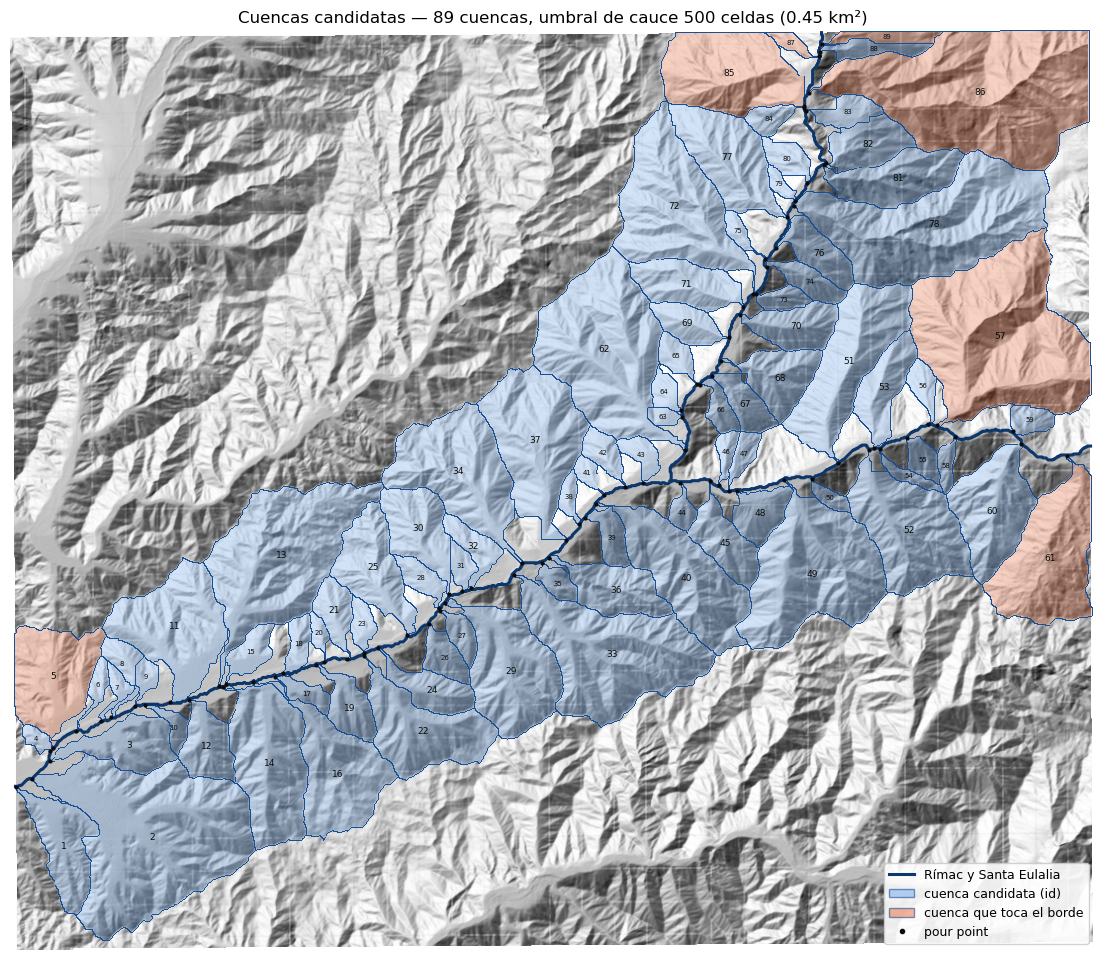

In [10]:
fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(hs, cmap="gray", vmin=-0.2, vmax=1.0)
# Cuencas: relleno suave; las que tocan el borde en naranja
relleno = np.ma.masked_where(ws == 0, np.where(toca[ws], 2, 1))
ax.imshow(relleno, cmap=ListedColormap(["#86b6ef", "#ec835a"]), vmin=1, vmax=2, alpha=0.35, interpolation="nearest")
# Límites entre cuencas
lim = (ws != np.roll(ws, 1, 0)) | (ws != np.roll(ws, 1, 1))
ax.imshow(np.ma.masked_where(~(lim & ((ws > 0) | (np.roll(ws, 1, 0) > 0) | (np.roll(ws, 1, 1) > 0))), lim),
          cmap=ListedColormap(["#184f95"]), interpolation="nearest")
# Cauce principal
for traza in (traza_rimac, traza_se):
    rr, cc = zip(*traza); ax.plot(cc, rr, color="#0d366b", lw=2.2)
# Etiquetas
cen = ndi.center_of_mass(ws > 0, ws, pp["cuenca_id"])
for cid, (r, c), a in zip(pp["cuenca_id"], cen, pp["area_km2"]):
    if ws[int(r), int(c)] != cid:            # si el centroide cae fuera, uso una celda de la cuenca
        r, c = np.argwhere(ws == cid)[len(np.argwhere(ws == cid)) // 2]
    ax.text(c, r, str(cid), fontsize=6.5 if a >= 1.5 else 5, ha="center", va="center", color="#0b0b0b")
ax.plot(pp["col"], pp["fila"], "o", ms=2, color="#0b0b0b")
from matplotlib.patches import Patch
ax.legend(handles=[Line2D([], [], color="#0d366b", lw=2.2, label="Rímac y Santa Eulalia"),
                   Patch(facecolor="#86b6ef", alpha=0.6, edgecolor="#184f95", label="cuenca candidata (id)"),
                   Patch(facecolor="#ec835a", alpha=0.6, edgecolor="#184f95", label="cuenca que toca el borde"),
                   Line2D([], [], marker="o", ls="", ms=3, color="#0b0b0b", label="pour point")],
          loc="lower right", fontsize=9, framealpha=0.9)
ax.set_title(f"Cuencas candidatas — {len(pp)} cuencas, umbral de cauce {UMBRAL_CAUCE} celdas ({UMBRAL_CAUCE*CELDA_M2/1e6:g} km²)", fontsize=12)
ax.set_axis_off()
fig.savefig(TERRENO / "cuencas_candidatas.png", dpi=170, bbox_inches="tight")
plt.show()

## Resumen fase 1

In [11]:
print(f"Corte para el cauce principal: {CORTE_PRINCIPAL:,} celdas + filtro 'drena al Rímac' + trazo D8 desde las entradas")
print(f"Cuencas candidatas: {len(pp)} (Rímac {int((pp.rio=='Rímac').sum())}, Santa Eulalia {int((pp.rio=='Santa Eulalia').sum())})")
print(f"Área: {pp.area_km2.min():.2f} – {pp.area_km2.max():.2f} km² (mediana {pp.area_km2.median():.2f})")
print(f"Tocan el borde: {int(pp.toca_borde.sum())} →", pp.loc[pp.toca_borde, ['cuenca_id', 'area_km2']].values.tolist())
print("Mayores:", pp.nlargest(8, 'area_km2')[['cuenca_id', 'rio', 'area_km2']].values.tolist())

Corte para el cauce principal: 50,000 celdas + filtro 'drena al Rímac' + trazo D8 desde las entradas
Cuencas candidatas: 89 (Rímac 61, Santa Eulalia 28)
Área: 0.45 – 23.34 km² (mediana 1.55)
Tocan el borde: 7 → [[5.0, 6.856], [57.0, 21.248], [61.0, 9.806], [85.0, 8.891], [86.0, 23.34], [87.0, 0.523], [89.0, 1.03]]
Mayores: [[86, 'Santa Eulalia', 23.34], [2, 'Rímac', 21.57], [57, 'Rímac', 21.248], [78, 'Santa Eulalia', 17.156], [62, 'Santa Eulalia', 15.088], [13, 'Rímac', 14.832], [33, 'Rímac', 13.888], [49, 'Rímac', 13.293]]
